# Task 4 — Optimise selected models

## 4.1 Seleção dos modelos para otimização

Com base nos resultados obtidos na Task 3, foram selecionados **três modelos** para a fase de otimização: **HistGradientBoosting, Random Forest e Logistic Regression**.

A seleção não considera apenas a PR-AUC média, mas também a estabilidade temporal, o desempenho com o limiar provisório, o custo computacional e a interpretabilidade dos modelos.

### HistGradientBoosting

O **HistGradientBoosting** apresentou a melhor PR-AUC média entre os modelos avaliados (0,6203), com um desvio-padrão de 0,0556. Foi superior à Decision Tree nos quatro folds temporais e apresentou um tempo médio de treino relativamente baixo (3,17 s por fold).

Estes resultados tornam-no o principal candidato para otimização.

### Random Forest

A **Random Forest** apresentou uma PR-AUC média de 0,6124, com um desvio-padrão de 0,0577, superando também a Decision Tree nos quatro folds temporais.

Além disso, apresentou o maior F2 médio (0,6088) com o limiar provisório utilizado na Task 3, sendo particularmente relevante num problema em que a deteção da classe positiva é importante.

A sua seleção permite também manter um modelo baseado num princípio diferente do Boosting, neste caso **bagging**.

### Logistic Regression

A **Logistic Regression** apresentou uma PR-AUC média inferior (0,5824), mas foi selecionada como alternativa mais simples e interpretável.

A sua inclusão permite avaliar se a otimização de um modelo de menor complexidade consegue aproximar o seu desempenho ao dos ensembles, mantendo simultaneamente uma maior facilidade de interpretação.

### Modelos não selecionados

O **Voting** não foi selecionado apesar da sua PR-AUC média competitiva (0,6128), uma vez que apresentou apenas uma melhoria muito pequena relativamente à Random Forest (0,6124) e um custo computacional consideravelmente superior.

A **Decision Tree** e o **Gaussian Naive Bayes** também não foram selecionados, uma vez que apresentaram desempenho inferior aos principais candidatos na comparação global.

Assim, os modelos entregues para a fase seguinte de otimização são:

1. **HistGradientBoosting**
2. **Random Forest**
3. **Logistic Regression**

A definição dos espaços de pesquisa, a otimização dos hiperparâmetros e a posterior seleção do limiar são realizadas nas secções seguintes.

### Preparação — Reutilização dos dados e do protocolo da Task 3

Esta secção reconstrói as variáveis necessárias em vez de depender de variáveis existentes na memória do `task3.ipynb`. Mantém-se o alvo baseado em `end_cause`, a lista `eligible_predictors`, as variáveis temporais cíclicas e as divisões temporais verificadas contra `validation_protocol_task2.json`.

In [1]:
import json
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (
    average_precision_score, precision_score, recall_score, f1_score,
    fbeta_score, confusion_matrix, roc_auc_score, brier_score_loss
)
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore", message="A worker stopped")

# Os três ficheiros devem estar na mesma pasta que este notebook.
DATA_PATH = Path("Charging_Data_educational.csv")
PROTOCOL_PATH = Path("validation_protocol_task2.json")
PREDICTORS_PATH = Path("predictors_task2.json")

for path in [DATA_PATH, PROTOCOL_PATH, PREDICTORS_PATH]:
    if not path.exists():
        raise FileNotFoundError(
            f"Não foi encontrado {path}. Coloca este ficheiro na mesma pasta que task4.ipynb."
        )

protocol = json.loads(PROTOCOL_PATH.read_text(encoding="utf-8"))
eligible_predictors = json.loads(PREDICTORS_PATH.read_text(encoding="utf-8"))["eligible_predictors"]

df = pd.read_csv(DATA_PATH)
df.columns = (
    df.columns.astype(str).str.strip().str.lower()
    .str.replace(r"[^a-zA-Z0-9]+", "_", regex=True).str.strip("_")
)

required_columns = {"start_time", "end_time", "end_cause"}
missing = required_columns - set(df.columns)
if missing:
    raise ValueError(f"Faltam colunas necessárias no CSV: {sorted(missing)}")

missing_predictors = set(eligible_predictors) - set(df.columns)
if missing_predictors:
    raise ValueError(f"Faltam preditores elegíveis no CSV: {sorted(missing_predictors)}")

start_dt = pd.to_datetime(df["start_time"], errors="coerce")
end_dt = pd.to_datetime(df["end_time"], errors="coerce")

NORMAL_END_CAUSES = {"Charging ends normally", "User stops charging"}
y = (~df["end_cause"].isin(NORMAL_END_CAUSES)).astype(int)

CATEGORICAL = ["charging_post_id", "location_information", "district_name", "tariff_period"]
missing_cat = set(CATEGORICAL) - set(eligible_predictors)
if missing_cat:
    raise ValueError(
        "A lista de preditores da Task 2 não contém as categóricas esperadas: "
        f"{sorted(missing_cat)}. Confirma o protocolo e a Task 3."
    )

def build_features(frame):
    X_local = frame[eligible_predictors].copy()

    # Variáveis cíclicas calculadas apenas a partir do início da sessão.
    hour = start_dt.dt.hour + start_dt.dt.minute / 60
    X_local["hour_sin"] = np.sin(2 * np.pi * hour / 24)
    X_local["hour_cos"] = np.cos(2 * np.pi * hour / 24)
    X_local["weekday_sin"] = np.sin(2 * np.pi * start_dt.dt.weekday / 7)
    X_local["weekday_cos"] = np.cos(2 * np.pi * start_dt.dt.weekday / 7)

    # start_time é representado pelas quatro variáveis cíclicas.
    if "start_time" in X_local.columns:
        X_local = X_local.drop(columns="start_time")

    X_local[CATEGORICAL] = X_local[CATEGORICAL].astype(str)
    numeric = [col for col in X_local.columns if col not in CATEGORICAL]
    X_local[numeric] = X_local[numeric].astype(float)
    return X_local

X = build_features(df)
numeric_cols = [col for col in X.columns if col not in CATEGORICAL]

TEST_START = pd.Timestamp(protocol["test_start"])
N_FOLDS = int(protocol["n_folds"])
FOLD_MONTHS = int(protocol["fold_months"])
val_starts = [
    TEST_START - pd.DateOffset(months=FOLD_MONTHS * (N_FOLDS - k))
    for k in range(N_FOLDS)
]
val_ends = val_starts[1:] + [TEST_START]

folds = []
for v_start, v_end in zip(val_starts, val_ends):
    val_idx = np.flatnonzero(((start_dt >= v_start) & (start_dt < v_end)).to_numpy())
    # Purga: a sessão tem de ter começado e terminado antes da validação.
    train_idx = np.flatnonzero(((start_dt < v_start) & (end_dt < v_start)).to_numpy())
    folds.append((train_idx, val_idx))

if len(protocol.get("folds", [])) != N_FOLDS:
    raise ValueError("O número de folds no protocolo não corresponde a n_folds.")

for k, (train_idx, val_idx) in enumerate(folds):
    expected = protocol["folds"][k]
    assert (len(train_idx), len(val_idx)) == (
        expected["n_treino"], expected["n_validacao"]
    ), f"Fold {k + 1} difere do protocolo da Task 2."

dev_mask = (start_dt < TEST_START).to_numpy()
THRESHOLD_PROVISIONAL = float(protocol["threshold_provisional"])

print(f"Folds temporais confirmados: {[(len(tr), len(va)) for tr, va in folds]}")
print(
    f"Preditores: {X.shape[1]} ({len(numeric_cols)} numéricos, "
    f"{len(CATEGORICAL)} categóricos)"
    f"\nPrevalência da classe anormal: {y.mean():.2%}"
)
print(f"Threshold provisório da Task 3: {THRESHOLD_PROVISIONAL:.2f}")
print(f"Início do teste final: {TEST_START}")

Folds temporais confirmados: [(79695, 66045), (145748, 57027), (202793, 42189), (244950, 64938)]
Preditores: 40 (36 numéricos, 4 categóricos)
Prevalência da classe anormal: 18.58%
Threshold provisório da Task 3: 0.20
Início do teste final: 2021-08-01 00:00:00


## Implementação dos modelos e pré-processamento

A PR-AUC (*Average Precision*) é a métrica principal porque a classe positiva — sessão anormal — é minoritária. Os espaços são deliberadamente limitados para permitir uma comparação reproduzível sem tornar o treino excessivamente dispendioso. 

- **Logistic Regression:** regularização `C` e ponderação das classes.
- **Random Forest:** número de árvores, profundidade, tamanho mínimo das folhas e número de variáveis consideradas por divisão.
- **HistGradientBoosting:** taxa de aprendizagem, número de iterações e complexidade das árvores.

As funções de construção reproduzem os pré-processadores utilizados na Task 3:
- **Logistic Regression:** imputação pela mediana e padronização das variáveis numéricas; one-hot encoding das categóricas.
- **Random Forest e HistGradientBoosting:** imputação pela mediana nas numéricas e `OrdinalEncoder` nas categóricas, tal como na implementação de ensembles da Task 3.

Os transformadores são colocados dentro de `Pipeline`, pelo que são ajustados apenas nos dados de treino de cada fold. A codificação ordinal das categorias nominais tem a limitação de criar uma ordem numérica artificial; é mantida aqui para preservar a comparabilidade com a Task 3 e deve ser mencionada como limitação.

In [2]:
RANDOM_STATE = 42
TREE_MIN_SAMPLES_LEAF = 200

def numeric_scaled():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

def make_logistic(C=1.0):
    prep = ColumnTransformer([
        ("num", numeric_scaled(), numeric_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=50), CATEGORICAL),
    ])
    return Pipeline([
        ("prep", prep),
        ("clf", LogisticRegression(C=C, max_iter=1000))
    ])

def ensemble_tree_preprocessor():
    return ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), numeric_cols),
        ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), CATEGORICAL),
    ])

def make_random_forest(
    n_estimators=100, max_depth=None,
    min_samples_leaf=TREE_MIN_SAMPLES_LEAF, max_features="sqrt"
):
    clf = RandomForestClassifier(
        n_estimators=n_estimators,
        max_depth=max_depth,
        min_samples_leaf=min_samples_leaf,
        max_features=max_features,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )
    return Pipeline([
        ("prep", ensemble_tree_preprocessor()),
        ("clf", clf)
    ])

def make_boosting(
    learning_rate=0.1, max_iter=100,
    max_leaf_nodes=31, l2_regularization=0.0
):
    clf = HistGradientBoostingClassifier(
        learning_rate=learning_rate,
        max_iter=max_iter,
        max_leaf_nodes=max_leaf_nodes,
        l2_regularization=l2_regularization,
        random_state=RANDOM_STATE,
    )
    return Pipeline([
        ("prep", ensemble_tree_preprocessor()),
        ("clf", clf)
    ])

def evaluate_fold(y_true, probabilities, threshold):
    pred = (probabilities >= threshold).astype(int)
    return {
        "PR-AUC (AP)": average_precision_score(y_true, probabilities),
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred, zero_division=0),
        "F1": f1_score(y_true, pred, zero_division=0),
        "F2": fbeta_score(y_true, pred, beta=2, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, probabilities),
        "Brier": brier_score_loss(y_true, probabilities),
        "Alertas por 1000": 1000 * pred.mean(),
    }

print("Modelos e pré-processamento preparados.")


Modelos e pré-processamento preparados.


## 4.2 Espaços de pesquisa dos hiperparâmetros

A pesquisa é deliberadamente pequena para manter o custo computacional controlado. Inclui-se a configuração de referência em cada modelo, para permitir uma comparação com a configuração inicial.

A pesquisa não garante encontrar o ótimo global: compara apenas as configurações explicitamente indicadas na tabela.

In [3]:
SEARCH_SPACES = {
    "Logistic Regression": [
        {"C": 0.1},
        {"C": 1.0},
        {"C": 10.0},
    ],
    "Random Forest": [
        {"n_estimators": 100, "max_depth": None, "min_samples_leaf": 200, "max_features": "sqrt"},
        {"n_estimators": 200, "max_depth": None, "min_samples_leaf": 200, "max_features": "sqrt"},
        {"n_estimators": 100, "max_depth": 16, "min_samples_leaf": 100, "max_features": "sqrt"},
        {"n_estimators": 200, "max_depth": 16, "min_samples_leaf": 200, "max_features": "sqrt"},
    ],
    "HistGradientBoosting": [
        {"learning_rate": 0.1, "max_iter": 100, "max_leaf_nodes": 31, "l2_regularization": 0.0},
        {"learning_rate": 0.05, "max_iter": 100, "max_leaf_nodes": 31, "l2_regularization": 0.0},
        {"learning_rate": 0.1, "max_iter": 200, "max_leaf_nodes": 31, "l2_regularization": 0.0},
        {"learning_rate": 0.1, "max_iter": 100, "max_leaf_nodes": 15, "l2_regularization": 1.0},
    ],
}

def build_candidate(model_name, params):
    if model_name == "Logistic Regression":
        return make_logistic(**params)
    if model_name == "Random Forest":
        return make_random_forest(**params)
    if model_name == "HistGradientBoosting":
        return make_boosting(**params)
    raise ValueError(f"Modelo desconhecido: {model_name}")

search_space_table = pd.DataFrame([
    {"Modelo": name, "Candidato": i + 1, "Hiperparâmetros": params}
    for name, candidates in SEARCH_SPACES.items()
    for i, params in enumerate(candidates)
])
display(search_space_table)
print("Número total de configurações:", len(search_space_table))


,Modelo,Candidato,Hiperparâmetros
0,Logistic Regression,1,{'C': 0.1}
1,Logistic Regression,2,{'C': 1.0}
2,Logistic Regression,3,{'C': 10.0}
3,Random Forest,1,"{'n_estimators': 100, 'max_depth': None, 'min_..."
4,Random Forest,2,"{'n_estimators': 200, 'max_depth': None, 'min_..."
5,Random Forest,3,"{'n_estimators': 100, 'max_depth': 16, 'min_sa..."
6,Random Forest,4,"{'n_estimators': 200, 'max_depth': 16, 'min_sa..."
7,HistGradientBoosting,1,"{'learning_rate': 0.1, 'max_iter': 100, 'max_l..."
8,HistGradientBoosting,2,"{'learning_rate': 0.05, 'max_iter': 100, 'max_..."
9,HistGradientBoosting,3,"{'learning_rate': 0.1, 'max_iter': 200, 'max_l..."


Número total de configurações: 11


### Interpretação dos resultados

A definição dos espaços de pesquisa resultou num total de **11 configurações de hiperparâmetros**, distribuídas por três modelos de classificação: Logistic Regression, Random Forest e HistGradientBoosting. Foram consideradas três configurações para a Logistic Regression e quatro para cada um dos modelos baseados em árvores.

Na **Logistic Regression**, a pesquisa permite avaliar o impacto da intensidade da regularização, através do hiperparâmetro `C`. São testados os valores 0.1, 1.0 e 10.0, permitindo comparar modelos com diferentes níveis de complexidade e perceber se uma regularização mais forte ou mais fraca favorece a capacidade de generalização.

Na **Random Forest**, são exploradas diferentes combinações do número de árvores (`n_estimators`), da profundidade máxima (`max_depth`) e do número mínimo de amostras por folha (`min_samples_leaf`). Estas configurações permitem analisar o impacto do tamanho da floresta e da complexidade das árvores no desempenho preditivo, procurando um equilíbrio entre a capacidade de identificar padrões nas sessões anormais e o risco de sobreajustamento.

No modelo **HistGradientBoosting**, a pesquisa incide sobre a taxa de aprendizagem (`learning_rate`), o número de iterações (`max_iter`), o número máximo de folhas por árvore (`max_leaf_nodes`) e a regularização L2 (`l2_regularization`). Estas variações permitem avaliar diferentes ritmos de aprendizagem e níveis de complexidade, bem como o efeito da regularização na generalização do modelo.

A pesquisa foi deliberadamente limitada para controlar o custo computacional e facilitar a comparação entre configurações. A inclusão de configurações de referência permite estabelecer uma base de comparação com as restantes alternativas. Contudo, os resultados obtidos apenas permitirão identificar a melhor configuração **entre as alternativas testadas**, não garantindo a descoberta do ótimo global.

A seleção final deverá basear-se nos resultados da validação temporal, utilizando a **Average Precision (PR-AUC) como métrica principal**, dada a distribuição desequilibrada das classes. A estabilidade do desempenho entre os diferentes períodos de validação e o custo computacional deverão também ser considerados na escolha da configuração final.

Importa salientar que a tabela apresentada descreve apenas os espaços de pesquisa definidos. A identificação da melhor configuração e a quantificação das melhorias obtidas dependem da execução da avaliação de cada candidato.

## 4.3 Otimização com os folds temporais

Cada configuração é treinada separadamente nos quatro folds. A métrica principal é a Average Precision, calculada nas probabilidades da classe anormal no período de validação. A melhor configuração de cada família é a que obtém a maior **AP média** entre os folds.

Também se guardam a AP por fold, o desvio-padrão e o tempo de ajuste. O desvio-padrão e o pior fold ajudam a interpretar a estabilidade, mas a regra automática de seleção abaixo maximiza a AP média.

In [4]:
def evaluate_candidate(model_name, params):
    fold_scores, fit_times = [], []
    for train_idx, val_idx in folds:
        model = build_candidate(model_name, params)
        started = time.perf_counter()
        model.fit(X.iloc[train_idx], y.iloc[train_idx])
        fit_times.append(time.perf_counter() - started)
        probabilities = model.predict_proba(X.iloc[val_idx])[:, 1]
        fold_scores.append(
            average_precision_score(y.iloc[val_idx], probabilities)
        )
    return fold_scores, fit_times

search_rows = []
search_results = {}
for model_name, candidates in SEARCH_SPACES.items():
    print(f"A otimizar {model_name}: {len(candidates)} configurações × {len(folds)} folds")
    for candidate_id, params in enumerate(candidates, start=1):
        scores, fit_times = evaluate_candidate(model_name, params)
        row = {
            "Modelo": model_name,
            "Candidato": candidate_id,
            "Hiperparâmetros": params,
            **{f"AP fold {k + 1}": score for k, score in enumerate(scores)},
            "AP média": float(np.mean(scores)),
            "AP std": float(np.std(scores, ddof=1)),
            "Pior fold AP": float(np.min(scores)),
            "Tempo médio/fold (s)": float(np.mean(fit_times)),
        }
        search_rows.append(row)
        search_results[(model_name, candidate_id)] = {
            "params": params, "scores": scores, "fit_times": fit_times
        }

search_table = pd.DataFrame(search_rows)
search_table = search_table.sort_values(
    ["Modelo", "AP média"], ascending=[True, False]
).reset_index(drop=True)
display(search_table.round(4))

best_params = {}
best_candidate_id = {}
for model_name in SEARCH_SPACES:
    model_rows = search_table[search_table["Modelo"] == model_name]
    best_row = model_rows.sort_values("AP média", ascending=False).iloc[0]
    best_params[model_name] = best_row["Hiperparâmetros"]
    best_candidate_id[model_name] = int(best_row["Candidato"])

best_config_table = (
    search_table.sort_values("AP média", ascending=False)
    .groupby("Modelo", as_index=False)
    .first()
    .set_index("Modelo")[["Candidato", "Hiperparâmetros", "AP média", "AP std", "Pior fold AP", "Tempo médio/fold (s)"]]
)
print("Melhor configuração encontrada em cada modelo:")
display(best_config_table.round(4))


A otimizar Logistic Regression: 3 configurações × 4 folds
A otimizar Random Forest: 4 configurações × 4 folds
A otimizar HistGradientBoosting: 4 configurações × 4 folds


,Modelo,Candidato,Hiperparâmetros,AP fold 1,AP fold 2,AP fold 3,AP fold 4,AP média,AP std,Pior fold AP,Tempo médio/fold (s)
0,HistGradientBoosting,2,"{'learning_rate': 0.05, 'max_iter': 100, 'max_...",0.6512,0.6162,0.5444,0.6717,0.6209,0.0559,0.5444,6.3749
1,HistGradientBoosting,1,"{'learning_rate': 0.1, 'max_iter': 100, 'max_l...",0.6499,0.6157,0.5454,0.6718,0.6207,0.0552,0.5454,4.3847
2,HistGradientBoosting,3,"{'learning_rate': 0.1, 'max_iter': 200, 'max_l...",0.6480,0.6157,0.5454,0.6710,0.6200,0.0547,0.5454,5.1295
3,HistGradientBoosting,4,"{'learning_rate': 0.1, 'max_iter': 100, 'max_l...",0.6528,0.6134,0.5407,0.6694,0.6191,0.0573,0.5407,3.4483
4,Logistic Regression,1,{'C': 0.1},0.6172,0.5782,0.5010,0.6353,0.5830,0.0596,0.5010,4.0334
5,Logistic Regression,2,{'C': 1.0},0.6159,0.5777,0.5010,0.6353,0.5825,0.0594,0.5010,4.2236
6,Logistic Regression,3,{'C': 10.0},0.6151,0.5771,0.5010,0.6353,0.5821,0.0592,0.5010,4.0183
7,Random Forest,3,"{'n_estimators': 100, 'max_depth': 16, 'min_sa...",0.6457,0.6132,0.5373,0.6679,0.6160,0.0571,0.5373,20.2531
8,Random Forest,2,"{'n_estimators': 200, 'max_depth': None, 'min_...",0.6435,0.6099,0.5333,0.6653,0.6130,0.0578,0.5333,35.8537
9,Random Forest,4,"{'n_estimators': 200, 'max_depth': 16, 'min_sa...",0.6422,0.6098,0.5338,0.6651,0.6127,0.0573,0.5338,31.0506


Melhor configuração encontrada em cada modelo:


,Candidato,Hiperparâmetros,AP média,AP std,Pior fold AP,Tempo médio/fold (s)
Modelo,,,,,,
HistGradientBoosting,2,"{'learning_rate': 0.05, 'max_iter': 100, 'max_...",0.6209,0.0559,0.5444,6.3749
Logistic Regression,1,{'C': 0.1},0.5830,0.0596,0.5010,4.0334
Random Forest,3,"{'n_estimators': 100, 'max_depth': 16, 'min_sa...",0.6160,0.0571,0.5373,20.2531


A otimização avaliou 11 configurações de hiperparâmetros através de quatro folds temporais, realizando um total de 44 ajustes de modelos. A seleção foi baseada na Average Precision (AP) média, por ser a métrica principal para a classificação das sessões anormais.

O HistGradientBoosting apresentou o melhor resultado, com uma AP média de 0.6209, utilizando o candidato 2 (learning_rate = 0.05 e max_iter = 100). A Random Forest obteve uma AP média de 0.6160, enquanto a Logistic Regression alcançou 0.5830.

Apesar de o HistGradientBoosting apresentar o melhor desempenho médio, a diferença relativamente à Random Forest é reduzida (0.0049). Além disso, a configuração selecionada demora, em média, 6.37 segundos por fold, enquanto a melhor Random Forest demora 20.25 segundos. A Logistic Regression é a alternativa mais rápida, com 4.03 segundos por fold, mas apresenta menor AP média.

Os desvios-padrão das melhores configurações variam entre 0.0559 e 0.0596, evidenciando alguma variação no desempenho entre períodos temporais. Em todos os modelos, a AP mais baixa ocorreu no terceiro fold.

Em conclusão, o HistGradientBoosting foi selecionado por apresentar a maior AP média entre as configurações testadas. Contudo, esta diferença deve ser interpretada com prudência, uma vez que os resultados dependem dos períodos de validação utilizados. A avaliação no conjunto de teste final permitirá analisar o desempenho do modelo em dados não utilizados durante a otimização.

## 4.4 Comparação: configuração inicial vs otimizada

A comparação utiliza os mesmos quatro folds e apresenta a diferença entre a AP da configuração otimizada e a configuração de referência. Um delta positivo significa que a AP aumentou nesse fold.

Como os mesmos folds participam na escolha dos hiperparâmetros, esta comparação é útil para diagnóstico e seleção, mas não deve ser interpretada como uma avaliação independente do ganho.

,Default AP média,Default AP std,Tuned AP média,Tuned AP std,Delta AP média,Folds tuned > default,Default tempo (s/fold),Tuned tempo (s/fold)
Modelo,,,,,,,,
Logistic Regression,0.5825,0.0594,0.5830,0.0596,0.0005,4/4,3.1406,3.1861
Random Forest,0.6124,0.0577,0.6160,0.0571,0.0037,4/4,15.3755,19.7382
HistGradientBoosting,0.6207,0.0552,0.6209,0.0559,0.0002,2/4,4.9302,6.0128


Delta por fold (positivo = tuned teve AP superior):


Modelo,HistGradientBoosting,Logistic Regression,Random Forest
Fold,,,
1,0.0013,0.0013,0.0028
2,0.0004,0.0005,0.0038
3,-0.0010,0.0000,0.0046
4,-0.0001,0.0000,0.0035


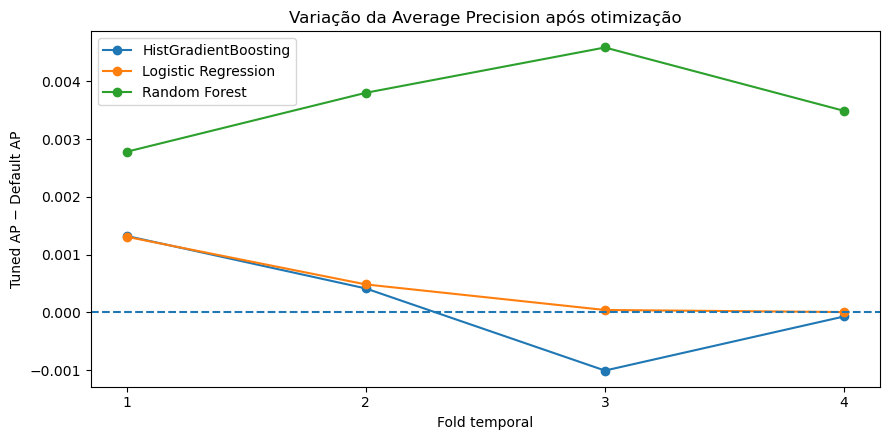

In [5]:
DEFAULT_BUILDERS = {
    "Logistic Regression": lambda: make_logistic(C=1.0),
    "Random Forest": lambda: make_random_forest(n_estimators=100, max_depth=None,
                                                 min_samples_leaf=TREE_MIN_SAMPLES_LEAF,
                                                 max_features="sqrt"),
    "HistGradientBoosting": lambda: make_boosting(learning_rate=0.1, max_iter=100,
                                                   max_leaf_nodes=31, l2_regularization=0.0),
}

def get_fold_ap(model_factory):
    values, seconds = [], []
    for train_idx, val_idx in folds:
        model = model_factory()
        started = time.perf_counter()
        model.fit(X.iloc[train_idx], y.iloc[train_idx])
        seconds.append(time.perf_counter() - started)
        prob = model.predict_proba(X.iloc[val_idx])[:, 1]
        values.append(average_precision_score(y.iloc[val_idx], prob))
    return values, seconds

comparison_rows, fold_comparison_rows = [], []
for name in SEARCH_SPACES:
    default_scores, default_times = get_fold_ap(DEFAULT_BUILDERS[name])
    tuned_scores, tuned_times = get_fold_ap(
        lambda n=name: build_candidate(n, best_params[n])
    )
    for fold_no, (default_ap, tuned_ap) in enumerate(zip(default_scores, tuned_scores), start=1):
        fold_comparison_rows.append({
            "Modelo": name, "Fold": fold_no,
            "Default AP": default_ap, "Tuned AP": tuned_ap,
            "Delta AP": tuned_ap - default_ap
        })
    comparison_rows.append({
        "Modelo": name,
        "Default AP média": np.mean(default_scores),
        "Default AP std": np.std(default_scores, ddof=1),
        "Tuned AP média": np.mean(tuned_scores),
        "Tuned AP std": np.std(tuned_scores, ddof=1),
        "Delta AP média": np.mean(tuned_scores) - np.mean(default_scores),
        "Folds tuned > default": f"{sum(t > d for t, d in zip(tuned_scores, default_scores))}/{len(folds)}",
        "Default tempo (s/fold)": np.mean(default_times),
        "Tuned tempo (s/fold)": np.mean(tuned_times),
    })

default_tuned_table = pd.DataFrame(comparison_rows).set_index("Modelo")
fold_default_tuned = pd.DataFrame(fold_comparison_rows)
display(default_tuned_table.round(4))
print("Delta por fold (positivo = tuned teve AP superior):")
display(fold_default_tuned.pivot(index="Fold", columns="Modelo", values="Delta AP").round(4))

fig, ax = plt.subplots(figsize=(9, 4.5))
for name, part in fold_default_tuned.groupby("Modelo"):
    ax.plot(part["Fold"], part["Delta AP"], marker="o", label=name)
ax.axhline(0, linestyle="--")
ax.set(
    title="Variação da Average Precision após otimização",
    xlabel="Fold temporal", ylabel="Tuned AP − Default AP",
    xticks=list(range(1, len(folds) + 1))
)
ax.legend()
plt.tight_layout()
plt.show()


A comparação entre as configurações iniciais e otimizadas revelou melhorias reduzidas na Average Precision (AP) média dos três modelos.

A Random Forest apresentou a maior melhoria, passando de uma AP média de 0.6124 para 0.6160 (+0.0037). A configuração otimizada obteve melhores resultados nos quatro folds, embora tenha aumentado o tempo médio de treino de 15.38 para 19.74 segundos por fold.

Na Logistic Regression, a AP média aumentou ligeiramente de 0.5825 para 0.5830 (+0.0005), com melhorias nos quatro folds. No entanto, este ganho é pouco expressivo e o tempo médio de treino aumentou ligeiramente.

O HistGradientBoosting apresentou a menor melhoria, passando de 0.6207 para 0.6209 (+0.0002). A configuração otimizada superou a inicial em apenas dois dos quatro folds e apresentou um aumento do tempo médio de treino de 4.93 para 6.01 segundos por fold.

Em conclusão, a otimização teve um impacto mais evidente na Random Forest, enquanto nos restantes modelos as diferenças foram praticamente residuais. Apesar disso, o HistGradientBoosting manteve a maior AP média absoluta (0.6209), seguido da Random Forest (0.6160) e da Logistic Regression (0.5830). A escolha final deverá considerar também o custo computacional e o desempenho no conjunto de teste independente, uma vez que os mesmos folds foram utilizados na seleção das configurações e nesta comparação.

## 4.5 Seleção do modelo probabilístico final

A regra automática seleciona o modelo cuja melhor configuração tem maior AP média nos folds de desenvolvimento. Antes de aceitar a escolha, deve também ser consultada a estabilidade (desvio-padrão e pior fold) e o custo de treino. O teste final não participa nesta decisão.

Se dois modelos apresentarem AP média muito próxima, a decisão deve ser justificada com a estabilidade, o custo computacional e a interpretabilidade, sem usar os resultados do teste final.

In [6]:
tuned_summary_rows = []
for name, params in best_params.items():
    row = search_table[
        (search_table["Modelo"] == name) &
        (search_table["Candidato"] == best_candidate_id[name])
    ].iloc[0]
    fold_values = [row[f"AP fold {k + 1}"] for k in range(len(folds))]
    tuned_summary_rows.append({
        "Modelo": name,
        "AP média": np.mean(fold_values),
        "AP std": np.std(fold_values, ddof=1),
        "Pior fold AP": np.min(fold_values),
        "Tempo médio/fold (s)": row["Tempo médio/fold (s)"],
        "Hiperparâmetros": params,
    })

tuned_summary = pd.DataFrame(tuned_summary_rows).sort_values(
    "AP média", ascending=False
).set_index("Modelo")
display(tuned_summary.round(4))

FINAL_MODEL_NAME = tuned_summary.index[0]
FINAL_PARAMS = best_params[FINAL_MODEL_NAME]
print("Modelo selecionado para a análise do limiar:", FINAL_MODEL_NAME)
print("Hiperparâmetros selecionados:", FINAL_PARAMS)

,AP média,AP std,Pior fold AP,Tempo médio/fold (s),Hiperparâmetros
Modelo,,,,,
HistGradientBoosting,0.6209,0.0559,0.5444,6.3749,"{'learning_rate': 0.05, 'max_iter': 100, 'max_..."
Random Forest,0.6160,0.0571,0.5373,20.2531,"{'n_estimators': 100, 'max_depth': 16, 'min_sa..."
Logistic Regression,0.5830,0.0596,0.5010,4.0334,{'C': 0.1}


Modelo selecionado para a análise do limiar: HistGradientBoosting
Hiperparâmetros selecionados: {'learning_rate': 0.05, 'max_iter': 100, 'max_leaf_nodes': 31, 'l2_regularization': 0.0}


A seleção do modelo probabilístico final foi realizada com base na Average Precision (AP) média obtida nos folds de desenvolvimento, considerando também a estabilidade dos resultados e o custo computacional de cada configuração.

O modelo HistGradientBoosting apresentou o melhor desempenho médio, com uma AP de 0,6209, um desvio-padrão de 0,0559 e uma AP mínima de 0,5444. O Random Forest obteve uma AP média de 0,6160, com um desvio-padrão de 0,0571 e um pior resultado de 0,5373. Embora a diferença de AP média entre estes dois modelos seja reduzida, o HistGradientBoosting apresentou resultados ligeiramente mais favoráveis tanto em termos de desempenho como de estabilidade.

Adicionalmente, o HistGradientBoosting apresentou um tempo médio de 6,3749 segundos por fold, consideravelmente inferior aos 20,2531 segundos registados pelo Random Forest. A Logistic Regression foi o modelo mais rápido, com 4,0334 segundos por fold, mas obteve uma AP média inferior, de 0,5830.

Assim, considerando conjuntamente o desempenho médio, a variabilidade entre folds, o pior resultado observado e o custo computacional, selecionou-se o HistGradientBoosting como modelo probabilístico final, com os hiperparâmetros learning_rate=0.05, max_iter=100, max_leaf_nodes=31 e l2_regularization=0.0.

Esta escolha define o modelo a utilizar na análise subsequente do limiar de classificação. O conjunto de teste final não foi utilizado na seleção, ficando reservado para a avaliação final independente do desempenho do modelo.

## 4.6 Seleção do limiar com previsões out-of-sample

O limiar de 0,50 é uma referência, mas não tem de ser o mais adequado para um problema em que a classe positiva é minoritária. Nesta secção, escolhe-se o limiar que maximiza o **F2**, uma métrica que dá mais peso ao recall.

As probabilidades usadas são out-of-fold (oof): cada previsão é feita por um modelo que não foi ajustado com as observações do respetivo período de validação. Existe, no entanto, uma limitação: os mesmos folds foram utilizados para escolher hiperparâmetros e limiar. Para uma separação metodológica mais rigorosa, seria necessário nested temporal CV ou um período de calibração separado. O teste final continua reservado e não é consultado nesta etapa.

Limiar escolhido por F2 máximo: 0.12


,Threshold,Precision,Recall,F1,F2,Alert rate,Alertas por 1000
7,0.12,0.3388,0.8292,0.4811,0.6431,0.4358,435.8273
15,0.20,0.4768,0.6559,0.5522,0.6101,0.2450,244.9880
45,0.50,0.7492,0.3987,0.5205,0.4399,0.0948,94.7789


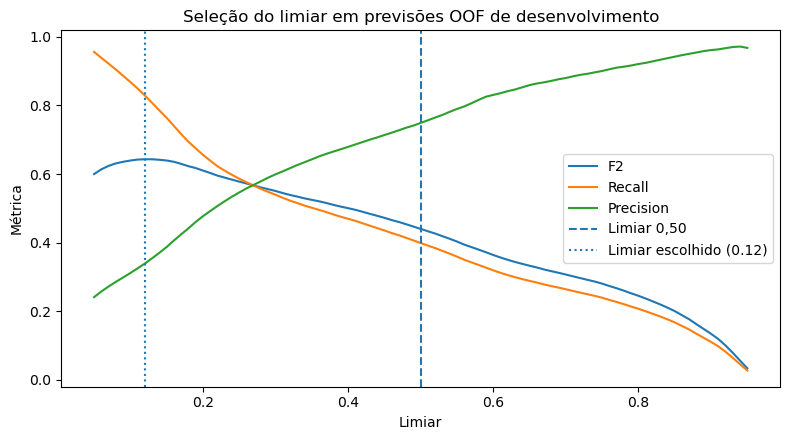

In [7]:
oof_parts = []
for fold_no, (train_idx, val_idx) in enumerate(folds, start=1):
    model = build_candidate(FINAL_MODEL_NAME, FINAL_PARAMS)
    model.fit(X.iloc[train_idx], y.iloc[train_idx])
    prob = model.predict_proba(X.iloc[val_idx])[:, 1]
    oof_parts.append(pd.DataFrame({
        "row_idx": val_idx,
        "fold": fold_no,
        "y_true": y.iloc[val_idx].to_numpy(),
        "probability": prob,
    }))

oof_predictions = pd.concat(oof_parts, ignore_index=True).sort_values("row_idx")
assert oof_predictions["row_idx"].is_unique

threshold_grid = np.unique(np.r_[np.arange(0.05, 0.951, 0.01), 0.5, THRESHOLD_PROVISIONAL])
threshold_rows = []
for threshold in threshold_grid:
    pred = (oof_predictions["probability"].to_numpy() >= threshold).astype(int)
    threshold_rows.append({
        "Threshold": float(threshold),
        "Precision": precision_score(oof_predictions["y_true"], pred, zero_division=0),
        "Recall": recall_score(oof_predictions["y_true"], pred, zero_division=0),
        "F1": f1_score(oof_predictions["y_true"], pred, zero_division=0),
        "F2": fbeta_score(oof_predictions["y_true"], pred, beta=2, zero_division=0),
        "Alert rate": pred.mean(),
        "Alertas por 1000": 1000 * pred.mean(),
    })

threshold_table = pd.DataFrame(threshold_rows)
max_f2 = threshold_table["F2"].max()
# Em caso de empate de F2, escolhe-se o maior limiar para reduzir alertas.
THRESHOLD_STAR = float(
    threshold_table.loc[threshold_table["F2"] >= max_f2 - 1e-12, "Threshold"].max()
)

print(f"Limiar escolhido por F2 máximo: {THRESHOLD_STAR:.2f}")
comparison_thresholds = sorted(set([0.50, THRESHOLD_PROVISIONAL, THRESHOLD_STAR]))
display(
    threshold_table[threshold_table["Threshold"].isin(comparison_thresholds)]
    .sort_values("Threshold").round(4)
)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(threshold_table["Threshold"], threshold_table["F2"], label="F2")
ax.plot(threshold_table["Threshold"], threshold_table["Recall"], label="Recall")
ax.plot(threshold_table["Threshold"], threshold_table["Precision"], label="Precision")
ax.axvline(0.50, linestyle="--", label="Limiar 0,50")
ax.axvline(THRESHOLD_STAR, linestyle=":", label=f"Limiar escolhido ({THRESHOLD_STAR:.2f})")
ax.set(xlabel="Limiar", ylabel="Métrica", title="Seleção do limiar em previsões OOF de desenvolvimento")
ax.legend()
plt.tight_layout()
plt.show()


A seleção do limiar de classificação foi realizada com base nas previsões out-of-fold (OOF) do modelo HistGradientBoosting selecionado na secção anterior. Esta abordagem permite obter previsões para observações que não foram utilizadas diretamente no treino do modelo responsável por cada previsão.

Foram avaliados vários limiares, entre 0,05 e 0,95, incluindo o limiar de referência de 0,50 e o limiar provisório. Para cada valor, calcularam-se a precision, o recall, o F1, o F2 e a taxa de alertas, permitindo analisar o compromisso entre a deteção de casos positivos e o volume de alertas gerado.

O limiar de 0,12 apresentou o maior F2, com um valor de 0,6431, um recall de 0,8292 e uma precision de 0,3388. Este resultado evidencia uma elevada capacidade de deteção da classe positiva, embora implique uma maior proporção de falsos positivos. A taxa de alertas foi de 43,58%, correspondendo a aproximadamente 436 alertas por cada 1.000 observações.

Em comparação, o limiar de 0,50 obteve um F2 de 0,4399, um recall de 0,3987 e uma precision de 0,7492. Embora apresente maior precision e gere menos alertas, este limiar deixa por identificar uma proporção substancialmente superior dos casos positivos. O limiar de 0,20 apresentou resultados intermédios, com um F2 de 0,6101, um recall de 0,6559 e uma taxa de alertas de 24,50%.

Assim, de acordo com o critério de maximização do F2 previamente definido, selecionou-se o limiar de 0,12 para a análise subsequente. Esta escolha privilegia o recall, em concordância com o objetivo de reduzir os casos positivos não detetados.

Importa, contudo, reconhecer que os mesmos folds temporais foram utilizados na seleção dos hiperparâmetros e na escolha do limiar, o que limita a independência desta avaliação. Uma abordagem metodologicamente mais rigorosa poderia recorrer a nested temporal cross-validation ou a um período de calibração separado. O conjunto de teste final permaneceu reservado, não tendo sido utilizado nesta etapa.

## 4.7 Congelamento das decisões e avaliação no teste final

Antes de consultar os resultados do teste final, ficam fixados:
- a família de modelo selecionada;
- os hiperparâmetros escolhidos;
- o limiar selecionado a partir das previsões de desenvolvimento.

O modelo é treinado com sessões elegíveis anteriores ao início do teste, aplicando a mesma regra de purga temporal: a sessão tem de ter começado e terminado antes de `TEST_START`.

A tabela compara o limiar de 0,50 com o limiar selecionado. Esta comparação é descritiva: não se deve escolher um novo limiar com base no teste final.

In [ ]:
# Congelar decisões antes de avaliar o teste final.
FROZEN_MODEL_NAME = FINAL_MODEL_NAME
FROZEN_PARAMS = dict(FINAL_PARAMS)
FROZEN_THRESHOLD = float(THRESHOLD_STAR)

final_train_mask = ((start_dt < TEST_START) & (end_dt < TEST_START)).to_numpy()
final_test_mask = (start_dt >= TEST_START).to_numpy()
final_train_idx = np.flatnonzero(final_train_mask)
final_test_idx = np.flatnonzero(final_test_mask)

if len(final_train_idx) == 0 or len(final_test_idx) == 0:
    raise ValueError("Treino final ou teste final vazio. Confirma TEST_START e o CSV.")

final_model = build_candidate(FROZEN_MODEL_NAME, FROZEN_PARAMS)
final_model.fit(X.iloc[final_train_idx], y.iloc[final_train_idx])
final_test_probability = final_model.predict_proba(X.iloc[final_test_idx])[:, 1]
y_test = y.iloc[final_test_idx].to_numpy()

def operational_metrics(y_true, probabilities, threshold):
    pred = (probabilities >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    n = len(y_true)
    return {
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred, zero_division=0),
        "F1": f1_score(y_true, pred, zero_division=0),
        "F2": fbeta_score(y_true, pred, beta=2, zero_division=0),
        "Alert rate": pred.mean(),
        "Alertas por 1000": 1000 * pred.mean(),
        "Alertas corretos / 1000 (TP)": 1000 * tp / n,
        "Falsos alertas / 1000 (FP)": 1000 * fp / n,
        "Anomalias perdidas / 1000 (FN)": 1000 * fn / n,
        "PR-AUC (AP)": average_precision_score(y_true, probabilities),
        "ROC-AUC": roc_auc_score(y_true, probabilities),
        "Brier": brier_score_loss(y_true, probabilities),
        "TP": tp, "FP": fp, "TN": tn, "FN": fn,
    }

final_threshold_table = pd.DataFrame([
    {"Limiar": 0.50, **operational_metrics(y_test, final_test_probability, 0.50)},
    {"Limiar": FROZEN_THRESHOLD, **operational_metrics(y_test, final_test_probability, FROZEN_THRESHOLD)},
]).set_index("Limiar")

print(f"Modelo congelado: {FROZEN_MODEL_NAME}")
print(f"Hiperparâmetros: {FROZEN_PARAMS}")
print(f"Treino final: {len(final_train_idx):,} | teste final: {len(final_test_idx):,}")
print(f"Limiar escolhido no desenvolvimento: {FROZEN_THRESHOLD:.2f}")
display(final_threshold_table.round(4))

Modelo congelado: HistGradientBoosting
Hiperparâmetros: {'learning_rate': 0.05, 'max_iter': 100, 'max_leaf_nodes': 31, 'l2_regularization': 0.0}
Treino final: 309,892 | teste final: 131,147
Limiar escolhido no desenvolvimento: 0.12


,Precision,Recall,F1,F2,Alert rate,Alertas por 1000,Alertas corretos / 1000 (TP),Falsos alertas / 1000 (FP),Anomalias perdidas / 1000 (FN),PR-AUC (AP),ROC-AUC,Brier,TP,FP,TN,FN
Limiar,,,,,,,,,,,,,,,,
0.50,0.7168,0.3472,0.4678,0.3871,0.0933,93.3380,66.9020,26.4360,125.7901,0.5934,0.8129,0.1146,8774,3467,102409,16497
0.12,0.3185,0.8427,0.4623,0.6340,0.5099,509.8782,162.3903,347.4879,30.3019,0.5934,0.8129,0.1146,21297,45572,60304,3974


### Interpretação operacional do limiar

Antes da avaliação do teste final, foram fixadas as decisões tomadas durante o desenvolvimento: a família de modelo HistGradientBoosting, os hiperparâmetros selecionados e o limiar de classificação de 0,12, escolhido pela maximização do F2 nas previsões out-of-fold.

O modelo final foi treinado com 309 892 sessões elegíveis anteriores ao início do período de teste, aplicando a regra de purga temporal definida. O conjunto de teste, constituído por 131 147 sessões, foi utilizado exclusivamente para avaliar o desempenho da solução selecionada.

A avaliação comparou os limiares de 0,50 e 0,12. Com o limiar de 0,50, obteve-se uma precision de 0,7168, um recall de 0,3472 e um F2 de 0,3871. Este limiar apresentou uma menor taxa de alertas, de aproximadamente 93 por cada 1 000 sessões, mas deixou por detetar cerca de 126 anomalias por cada 1 000 sessões.

Com o limiar de 0,12, o recall aumentou para 0,8427 e o F2 para 0,6340, enquanto a precision diminuiu para 0,3185. Este resultado corresponde a aproximadamente 510 alertas por cada 1 000 sessões e a cerca de 30 anomalias perdidas por cada 1 000 sessões. Assim, o limiar selecionado no desenvolvimento permitiu detetar uma proporção substancialmente superior das anomalias no teste final, à custa de um aumento considerável dos falsos alertas.

As métricas dependentes do limiar evidenciam, portanto, o compromisso entre a capacidade de deteção e o custo operacional dos alertas. A AP foi de 0,5934, a ROC-AUC de 0,8129 e o Brier de 0,1146, sendo estes indicadores calculados a partir das probabilidades previstas e, por isso, iguais para ambos os limiares.

Em conclusão, manteve-se o limiar de 0,12, uma vez que foi selecionado exclusivamente com dados de desenvolvimento e privilegia a deteção da classe positiva. Os resultados do teste final foram utilizados para caracterizar o desempenho e as implicações operacionais da solução, sem proceder a uma nova seleção do limiar. A utilização dos mesmos folds na seleção dos hiperparâmetros e do limiar constitui uma limitação metodológica que deverá ser considerada na interpretação dos resultados.

## 4.8 Interpretação do modelo

A interpretabilidade é realizada de acordo com o modelo final selecionado, utilizando exclusivamente dados da fase de desenvolvimento. Quando o modelo selecionado é a *Logistic Regression*, são analisados os coeficientes e os respetivos *odds ratios*, permitindo compreender a direção e a intensidade da associação entre as variáveis e a probabilidade estimada de uma sessão ser anormal. Os coeficientes são interpretados no espaço transformado, considerando a padronização das variáveis numéricas e a codificação *one-hot* das variáveis categóricas.

Para os modelos baseados em árvores, a interpretabilidade é efetuada através da importância por permutação (*permutation importance*), calculada na última janela de validação temporal da fase de desenvolvimento. Esta abordagem mede a diminuição média da *Average Precision* (AP) quando os valores de cada variável são permutados, permitindo avaliar a contribuição de cada variável para o desempenho preditivo do modelo.

A análise não utiliza os rótulos do teste final para selecionar ou ordenar variáveis, preservando a independência da avaliação final. No entanto, os resultados devem ser interpretados com cautela: os coeficientes representam associações condicionais, enquanto a importância por permutação pode ser afetada pela correlação entre variáveis. Nenhuma destas medidas permite estabelecer relações de causalidade.

,Feature,Mean AP decrease,Std AP decrease
10,post_previous_abnormal_rate_1d,0.22199,0.00055
19,post_hours_since_previous_completed_abnormal,0.02756,0.00056
13,post_previous_abnormal_rate_7d,0.02323,0.00118
33,user_days_since_previous_completed_abnormal,0.01268,0.00022
16,post_previous_abnormal_rate_30d,0.01099,0.00008
24,user_previous_abnormal_rate_30d,0.00657,0.00020
30,user_previous_abnormal_rate_730d,0.00649,0.00010
8,post_previous_sessions_1d,0.00345,0.00026
0,charging_post_id,0.00341,0.00026
17,post_hours_since_previous_completed_session,0.00179,0.00011


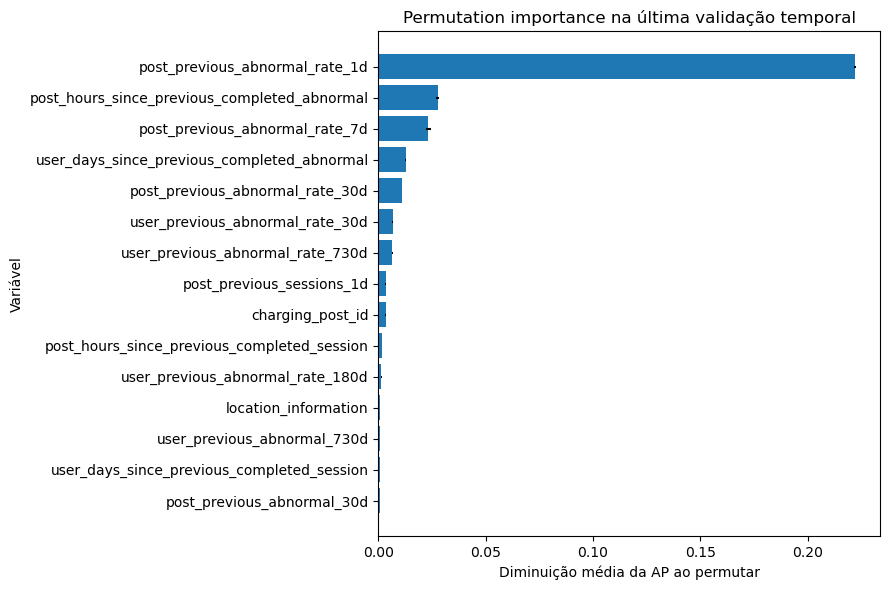

In [9]:
if FROZEN_MODEL_NAME == "Logistic Regression":
    feature_names = final_model.named_steps["prep"].get_feature_names_out()
    coef = pd.Series(final_model.named_steps["clf"].coef_[0], index=feature_names)
    coef_table = pd.DataFrame({
        "Coeficiente": coef,
        "Odds ratio": np.exp(np.clip(coef, -20, 20)),
        "Valor absoluto": coef.abs(),
    })
    print("Coeficientes com maior valor absoluto:")
    display(coef_table.sort_values("Valor absoluto", ascending=False).head(20).round(4))
else:
    # Importância na última validação temporal de desenvolvimento; não usa o teste final.
    importance_train_idx, importance_val_idx = folds[-1]
    importance_model = build_candidate(FROZEN_MODEL_NAME, FROZEN_PARAMS)
    importance_model.fit(X.iloc[importance_train_idx], y.iloc[importance_train_idx])
    perm = permutation_importance(
        importance_model,
        X.iloc[importance_val_idx],
        y.iloc[importance_val_idx],
        scoring="average_precision",
        n_repeats=3,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )
    importance_table = pd.DataFrame({
        "Feature": X.columns,
        "Mean AP decrease": perm.importances_mean,
        "Std AP decrease": perm.importances_std,
    }).sort_values("Mean AP decrease", ascending=False)
    display(importance_table.head(20).round(5))

    top = importance_table.head(15).sort_values("Mean AP decrease")
    fig, ax = plt.subplots(figsize=(9, 6))
    ax.barh(top["Feature"], top["Mean AP decrease"], xerr=top["Std AP decrease"])
    ax.set(
        title="Permutation importance na última validação temporal",
        xlabel="Diminuição média da AP ao permutar",
        ylabel="Variável",
    )
    plt.tight_layout()
    plt.show()

Como o modelo final selecionado foi o HistGradientBoosting, a interpretabilidade foi realizada através da importância por permutação, utilizando exclusivamente dados da fase de desenvolvimento. A análise foi efetuada na última janela de validação temporal, medindo a diminuição da Average Precision (AP) após a permutação dos valores de cada variável.

Os resultados mostram que post_previous_abnormal_rate_1d é a variável com maior importância, apresentando uma diminuição média da AP de 0,22199. Este valor é substancialmente superior ao das restantes variáveis, sugerindo que a taxa de anomalias registadas no posto durante o período recente de um dia contém informação preditiva particularmente relevante para o modelo.

Seguem-se post_hours_since_previous_completed_abnormal, com uma diminuição média da AP de 0,02756, e post_previous_abnormal_rate_7d, com 0,02323. Estes resultados reforçam a relevância do histórico recente de anomalias dos postos de carregamento. A variável user_days_since_previous_completed_abnormal, com uma diminuição de 0,01268, evidencia também a contribuição do histórico individual dos utilizadores.

As taxas de anomalias dos utilizadores em janelas de 30 e 730 dias apresentam igualmente contributos positivos, embora inferiores aos das principais variáveis associadas aos postos. Em contrapartida, variáveis como location_information e charging_post_id apresentam diminuições médias da AP mais reduzidas, sugerindo uma contribuição preditiva individual menos expressiva nesta janela de validação.

De forma geral, os resultados indicam que o modelo utiliza sobretudo informação histórica recente dos postos de carregamento, complementada pelo histórico dos utilizadores. Esta interpretação deve, contudo, considerar a possível correlação entre variáveis e a necessidade de garantir que todas as informações históricas estavam efetivamente disponíveis no momento da previsão. A importância por permutação mede a contribuição preditiva das variáveis para o modelo, não permitindo estabelecer relações de causalidade.

A análise foi realizada sem utilizar os rótulos do teste final para selecionar ou ordenar variáveis, preservando a independência da avaliação final.

## 4.9 Conclusões quantitativas e limitações metodológicas

Os resultados obtidos permitem comparar o desempenho dos três modelos considerados, avaliar o efeito da otimização dos hiperparâmetros e selecionar uma configuração final para a deteção de sessões de carregamento anómalas. A comparação foi realizada com base na Average Precision (AP) média e no respetivo desvio-padrão nos quatro folds temporais de desenvolvimento, complementando esta análise com o pior resultado observado e o custo computacional. A configuração vencedora do HistGradientBoosting apresentou uma AP média de 0,6209 ± 0,0559, com uma AP de 0,5444 no pior fold e um tempo médio de treino de aproximadamente 6,37 segundos por fold. Para o Random Forest, obteve-se uma AP média de 0,6160 ± 0,0571, uma AP mínima de 0,5373 e um tempo médio de aproximadamente 20,25 segundos por fold. Por sua vez, a Logistic Regression apresentou uma AP média de 0,5830 ± 0,0596, uma AP mínima de 0,5010 e um tempo médio de aproximadamente 4,03 segundos por fold. Estes resultados mostram que o HistGradientBoosting obteve o melhor desempenho médio e o melhor resultado no pior fold, mantendo um custo computacional substancialmente inferior ao do Random Forest. Embora a Logistic Regression tenha sido o modelo mais rápido, apresentou um desempenho inferior. Assim, o HistGradientBoosting foi selecionado como modelo final com base nos resultados de desenvolvimento, considerando conjuntamente a AP, a variabilidade entre folds, o pior resultado observado e o tempo de treino, sem utilizar as métricas do conjunto de teste para tomar esta decisão. A configuração selecionada utilizou `learning_rate=0.05`, `max_iter=100`, `max_leaf_nodes=31` e `l2_regularization=0.0`.

A comparação entre as configurações iniciais e otimizadas revelou que o efeito da otimização variou consoante o modelo. No Random Forest, a AP média aumentou de 0,6124 para 0,6160, correspondendo a uma melhoria de aproximadamente 0,0037, observada nos quatro folds. O desvio-padrão diminuiu ligeiramente, de 0,0577 para 0,0571, embora o tempo médio de treino tenha aumentado de aproximadamente 15,38 para 19,74 segundos por fold. Este foi o modelo que apresentou o ganho mais consistente e expressivo com a otimização. Na Logistic Regression, a AP média aumentou de 0,5825 para 0,5830, correspondendo a uma melhoria de apenas 0,0005, pelo que o benefício foi reduzido. Apesar de a tabela-resumo indicar melhorias em quatro dos quatro folds, os deltas apresentados individualmente incluem dois valores de 0,0000 à precisão de quatro casas decimais, sendo necessário confirmar os valores não arredondados para distinguir melhorias muito pequenas de empates. No HistGradientBoosting, a AP média passou de 0,6207 para 0,6209, um aumento de apenas 0,0002, tendo a configuração otimizada superado a inicial em dois dos quatro folds. Adicionalmente, o desvio-padrão aumentou de 0,0552 para 0,0559 e o tempo médio de treino passou de 4,93 para 6,01 segundos por fold. Consequentemente, a otimização produziu uma melhoria limitada neste último modelo, que já apresentava um desempenho inicial elevado. Importa salientar que a comparação entre as configurações iniciais e otimizadas utiliza folds que também participaram na seleção dos hiperparâmetros, pelo que os ganhos observados podem sobrestimar a melhoria que seria obtida em dados totalmente independentes.

Após a seleção do modelo, foi necessário determinar o limiar de classificação a utilizar para distinguir as sessões anómalas das sessões normais. Esta decisão foi baseada nas previsões out-of-fold (OOF), utilizando a métrica F2, que atribui maior importância ao recall do que à precisão. Foram comparados os limiares de 0,12, 0,20 e 0,50. Para o limiar de 0,12, obtiveram-se precisão de 0,3388, recall de 0,8292, F1 de 0,4811, F2 de 0,6431 e uma taxa de alertas de 43,58%, equivalente a aproximadamente 435,83 alertas por cada 1000 sessões. Com o limiar de 0,20, a precisão foi de 0,4768, o recall de 0,6559, o F1 de 0,5522 e o F2 de 0,6101, correspondendo a uma taxa de alertas de 24,50%. Por sua vez, o limiar de 0,50 apresentou uma precisão de 0,7492, um recall de 0,3987, um F1 de 0,5205 e um F2 de 0,4399, com uma taxa de alertas de 9,48%. O limiar de 0,12 foi selecionado por apresentar o maior F2, privilegiando a deteção de anomalias e a redução dos falsos negativos, mesmo à custa de um aumento dos falsos positivos. Esta escolha é adequada quando não detetar uma sessão anómala é considerado mais prejudicial do que gerar um alerta incorreto. No entanto, as previsões OOF não garantem, por si só, uma seleção totalmente independente do limiar, uma vez que os hiperparâmetros foram escolhidos utilizando os mesmos períodos temporais. Uma calibração estritamente independente exigiria validação temporal aninhada (*nested temporal cross-validation*) ou um período de calibração separado.

A avaliação final foi realizada no conjunto de teste, composto por 131 147 sessões, mantendo o modelo e os limiares previamente definidos. O treino incluiu 309 892 sessões, tendo sido aplicada uma separação temporal destinada a evitar que sessões que atravessassem o limite entre os períodos fossem utilizadas no treino. Com o limiar de 0,50, o modelo obteve uma precisão de 0,7168, um recall de 0,3472 e um F1 de 0,4678. A taxa de alertas foi de 9,33%, com aproximadamente 66,90 verdadeiros positivos, 26,44 falsos positivos e 125,79 falsos negativos por cada 1000 sessões. Estes resultados mostram que o limiar convencional produz menos alertas e uma proporção superior de alertas corretos, mas deixa por detetar uma parte considerável das anomalias. Com o limiar selecionado de 0,12, a precisão diminuiu para 0,3185, enquanto o recall aumentou para 0,8427. O F1 foi de 0,4623 e a taxa de alertas aumentou para 50,99%. Por cada 1000 sessões, foram identificados aproximadamente 162,39 verdadeiros positivos, mas também foram gerados 347,49 falsos positivos; o número de falsos negativos diminuiu para 30,30. Assim, a utilização do limiar de 0,12 permitiu detetar uma proporção muito superior das anomalias, reduzindo substancialmente as que não foram identificadas, mas originou um volume elevado de alertas incorretos. O F1 diminuiu ligeiramente em relação ao limiar de 0,50, demonstrando que o aumento do recall não se traduziu numa melhoria desta métrica, devido à redução da precisão. A AP, a ROC-AUC e o Brier score mantiveram-se, respetivamente, em 0,5934, 0,8129 e 0,1146 para ambos os limiares, uma vez que estas métricas dependem das probabilidades previstas e não da classificação binária obtida após a aplicação do limiar. A AP de teste foi inferior à AP média de desenvolvimento, que era de 0,6209, indicando uma diminuição do desempenho no período não utilizado no desenvolvimento. Contudo, esta diferença, isoladamente, não permite concluir que exista sobreajustamento, podendo também refletir alterações temporais na distribuição ou na dificuldade das sessões. O limiar de 0,12 representa, assim, uma opção orientada para a deteção de anomalias, mas a sua utilização prática depende da capacidade operacional para analisar aproximadamente metade das sessões sinalizadas. O limiar de 0,50 poderá ser mais adequado quando a capacidade de análise é limitada e se pretende reduzir os falsos alarmes, aceitando-se, em contrapartida, um maior número de anomalias não detetadas. A escolha entre estes limiares deve, por isso, considerar os custos reais dos dois tipos de erro, sem reajustar o modelo com base nos resultados do teste final.

A interpretação das variáveis através da importância por permutação, calculada numa janela temporal de validação, revelou que `post_previous_abnormal_rate_1d` foi a variável mais influente, com uma diminuição média da AP de 0,22199 quando os seus valores foram permutados. Seguiram-se `post_hours_since_previous_completed_abnormal`, com 0,02756, e `post_previous_abnormal_rate_7d`, com 0,02323. Estes resultados evidenciam a importância do histórico recente de anomalias associado ao posto de carregamento. As variáveis relacionadas com o histórico do utilizador também contribuíram para as previsões, nomeadamente `user_days_since_previous_completed_abnormal`, com uma diminuição média da AP de 0,01268, e `user_previous_abnormal_rate_30d`, com 0,00657. Em contrapartida, variáveis como `location_information` apresentaram uma contribuição adicional reduzida nesta análise. Importa esclarecer que `is_abnormal`, a variável-alvo, e `post_previous_abnormal_rate_1d`, uma variável preditora histórica, já existiam no conjunto de dados original. A existência destas variáveis não constitui, por si só, uma limitação; contudo, é fundamental confirmar que a variável-alvo é utilizada apenas como resultado a prever e que as variáveis históricas são calculadas exclusivamente com informação disponível antes da sessão em análise. Caso contrário, poderá ocorrer fuga de informação temporal, conduzindo a estimativas de desempenho excessivamente otimistas. Além disso, a importância por permutação identifica a contribuição preditiva das variáveis, mas não demonstra uma relação causal. A elevada importância do histórico de anomalias do posto indica que essa informação ajuda o modelo a distinguir sessões anómalas, mas não prova que as anomalias anteriores causem as anomalias futuras. A existência de variáveis correlacionadas pode ainda distribuir a importância entre diferentes atributos, pelo que uma importância individual reduzida não significa necessariamente ausência de informação útil.

Por fim, os resultados devem ser interpretados tendo em conta várias limitações metodológicas. Em primeiro lugar, a pesquisa de hiperparâmetros foi deliberadamente limitada, pelo que a melhor configuração identificada corresponde à melhor alternativa entre as configurações testadas, não existindo garantia de que represente o ótimo global. Em segundo lugar, a comparação entre as configurações iniciais e otimizadas foi realizada nos mesmos folds que participaram na seleção dos hiperparâmetros, o que poderá sobrestimar os ganhos da otimização. Em terceiro lugar, embora as previsões OOF evitem prever cada observação com um modelo ajustado diretamente nessa mesma observação, a seleção dos hiperparâmetros utilizou os mesmos períodos, pelo que a escolha do limiar não é totalmente independente. Uma validação temporal aninhada ou um período de calibração separado permitiria avaliar esta decisão com maior rigor. Em quarto lugar, a codificação ordinal de variáveis categóricas utilizada nos modelos de árvores pode introduzir uma ordem artificial entre categorias que não possuem uma relação naturalmente ordenada, influenciando as divisões efetuadas pelos modelos. A estratégia de codificação deve, por isso, ser adequada à natureza de cada variável e aplicada sem utilizar informação dos conjuntos de validação ou de teste no ajuste do pré-processamento. Adicionalmente, a validade dos resultados depende de todas as variáveis preditoras estarem disponíveis no momento da previsão e de o histórico ser construído exclusivamente a partir de informação passada. A evolução temporal dos comportamentos dos utilizadores e dos postos de carregamento poderá também alterar o desempenho do modelo em períodos futuros, justificando a monitorização contínua das métricas. Por último, o conjunto de teste só constitui uma avaliação independente se os seus resultados não forem utilizados para selecionar hiperparâmetros, reajustar o limiar ou orientar outras decisões de desenvolvimento. Se forem introduzidas alterações com base nesses resultados, será necessário recorrer a um novo período de teste para obter uma avaliação independente.

Em conclusão, o HistGradientBoosting apresentou o melhor equilíbrio entre desempenho preditivo, resultado no pior fold e custo computacional, tendo sido selecionado com base nos resultados de desenvolvimento. O limiar de 0,12 favoreceu a deteção de anomalias e permitiu alcançar um recall de 84,27% no teste, embora tenha produzido uma taxa de alertas de 50,99% e um número elevado de falsos positivos. A análise interpretativa destacou sobretudo o histórico recente de anomalias do posto de carregamento, complementado pelo histórico do utilizador. Apesar dos resultados promissores, a utilização prática do modelo exige atenção à fuga de informação temporal, à independência da seleção do limiar, à estabilidade do desempenho em novos períodos e ao custo operacional dos alertas gerados.